In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
# The solver, loader, plot and Excel export all live in fast_solver.py so there
# is only one copy to maintain. Re-run this cell after editing that file.
%load_ext autoreload
%autoreload 2

from fast_solver import (
    load_avail_from_csv,
    solve_full_collection_with_fill,
    validate_solution,
    draw_solution,
    export_solution_to_excel,
)


# run this

In [2]:
# ── EDIT THIS CELL ───────────────────────────────────────────────────────────
CSV_PATH       = "Original.csv"
EXCEL_OUT      = "Plant.xlsx"
LOG            = False   # per-step progress from the solver module
SOLVER_LOG     = False   # OR-Tools internals; very verbose
MAX_SOLVE_SECS = 15      # ignored when RUN_TO_OPTIMAL = True
RUN_TO_OPTIMAL = True   # True = no time limit, run until both phases prove optimal
WORKERS        = 8
FILL_SIZE      = 2       # size of the fill extras: 2 = 2x2, 3 = 3x3
FILL_LEFTOVERS = True   # True = also paint every remaining free cell as an extra 1x1
STRUCTURE_SYMMETRY = True  # True = mirror structures across the in-game axis (never costs fill; monsters stay free)
GRADIENT_GAP       = 0.01  # last (tidy-up) step stops once within 1% of its best; never affects fill/income/symmetry
GRADIENT_MAX_SECS  = 160   # hard cap on that last step, even with RUN_TO_OPTIMAL
HEIGHT_MODE        = "game"  # "game" = big pieces toward the in-game top (along the mirror axis); "rows" = old grid-row way
FLIP_UP            = False   # True if the yellow 'in-game up' arrow points the wrong way for this island

# structures = {4: 3,  3: 8, 2: 0,  1: 10+1} # PN
structures = {4: 3,  3: 8, 2: 0,  1: 10} # N

monsters = {4: 1*3, 3: 1*3, 2: 14*3+3+7, 1: 3*3+14, "beds": 36}  # Plant
# monsters = {4: 1*3, 3: 3*3, 2: 12*3+3+7, 1: 3*3+14, "beds": 36} # Cold
# monsters = {4: 1*3+8,  3: 2*3  , 2: 16*3+2,   1: 1*3+70} # Air
# monsters = {4: 1*3+6,  3: 4*3+1, 2: 12*3+2,   1: 2*3+70} # Water
# monsters = {4: 1*3+10, 3: 1*3  , 2: 13*3+2,   1: 4*3+70} # Earth
# monsters = {4: 1*3+6,  3: 2*3  , 2: 14*3+1,   1: 2*3+70} # Haven
# monsters = {4: 0     , 3: 3*3  , 2: 10*3       , 1: 0}      # Crystal
# monsters = {4: 1, 3: 4*3  , 2: 14*3+7+24+7 , 1: 2*3+14+91} # Light

# ── Income mode (optional) ───────────────────────────────────────────────────
# USE_INCOME = True: the solver picks which extra monsters to add to earn the most.
# Then `monsters` above must hold ONLY the fixed part (what you always place),
# without the extras you used to add by hand (e.g. the +10 / +26 parts).
# Fill squares are not used in this mode - the extras ARE the fill.
# Add "beds": N to `monsters` (your remaining beds): the extras must use exactly N beds,
#   e.g. monsters = {4: 1*3, 3: 3*3, 2: 12*3+1, 1: 3*3, "beds": 40}
USE_INCOME = True
monster_catalog = [
    # income = per monster, any unit, same unit for every entry.
    # beds   = beds one of these takes (default 1)
    # optional: "min": at least this many, "max": at most this many (default: as many as fit)
    # extras are kept at the back of the island so they hide nothing (layout only, never costs income);
    #           add "back": False to an entry to let it sit anywhere
    {"name": "Wubbox",  "size": 4, "income": 750855, "beds": 1},
    {"name": "Werdo",   "size": 2, "income": 408799, "beds": 1},
    {"name": "Dipster", "size": 1, "income": 23483,  "beds": 0},
]


Structures: {1: 10, 2: 0, 3: 8, 4: 3}
Monsters:   {1: 24, 2: 75, 3: 3, 4: 16}
Extras:     {'Wubbox': 13, 'Werdo': 23, 'Dipster': 1}
Beds:       36/36 used
Income:     19,186,975  (proven maximum)
Free cells: 0
Symmetry:   21/21 structures mirrored  (proven best)
Gradient:   within 11.0% of best
Time:       13.51s packing + 188.03s symmetry + 160.43s layout  (363.15s total)


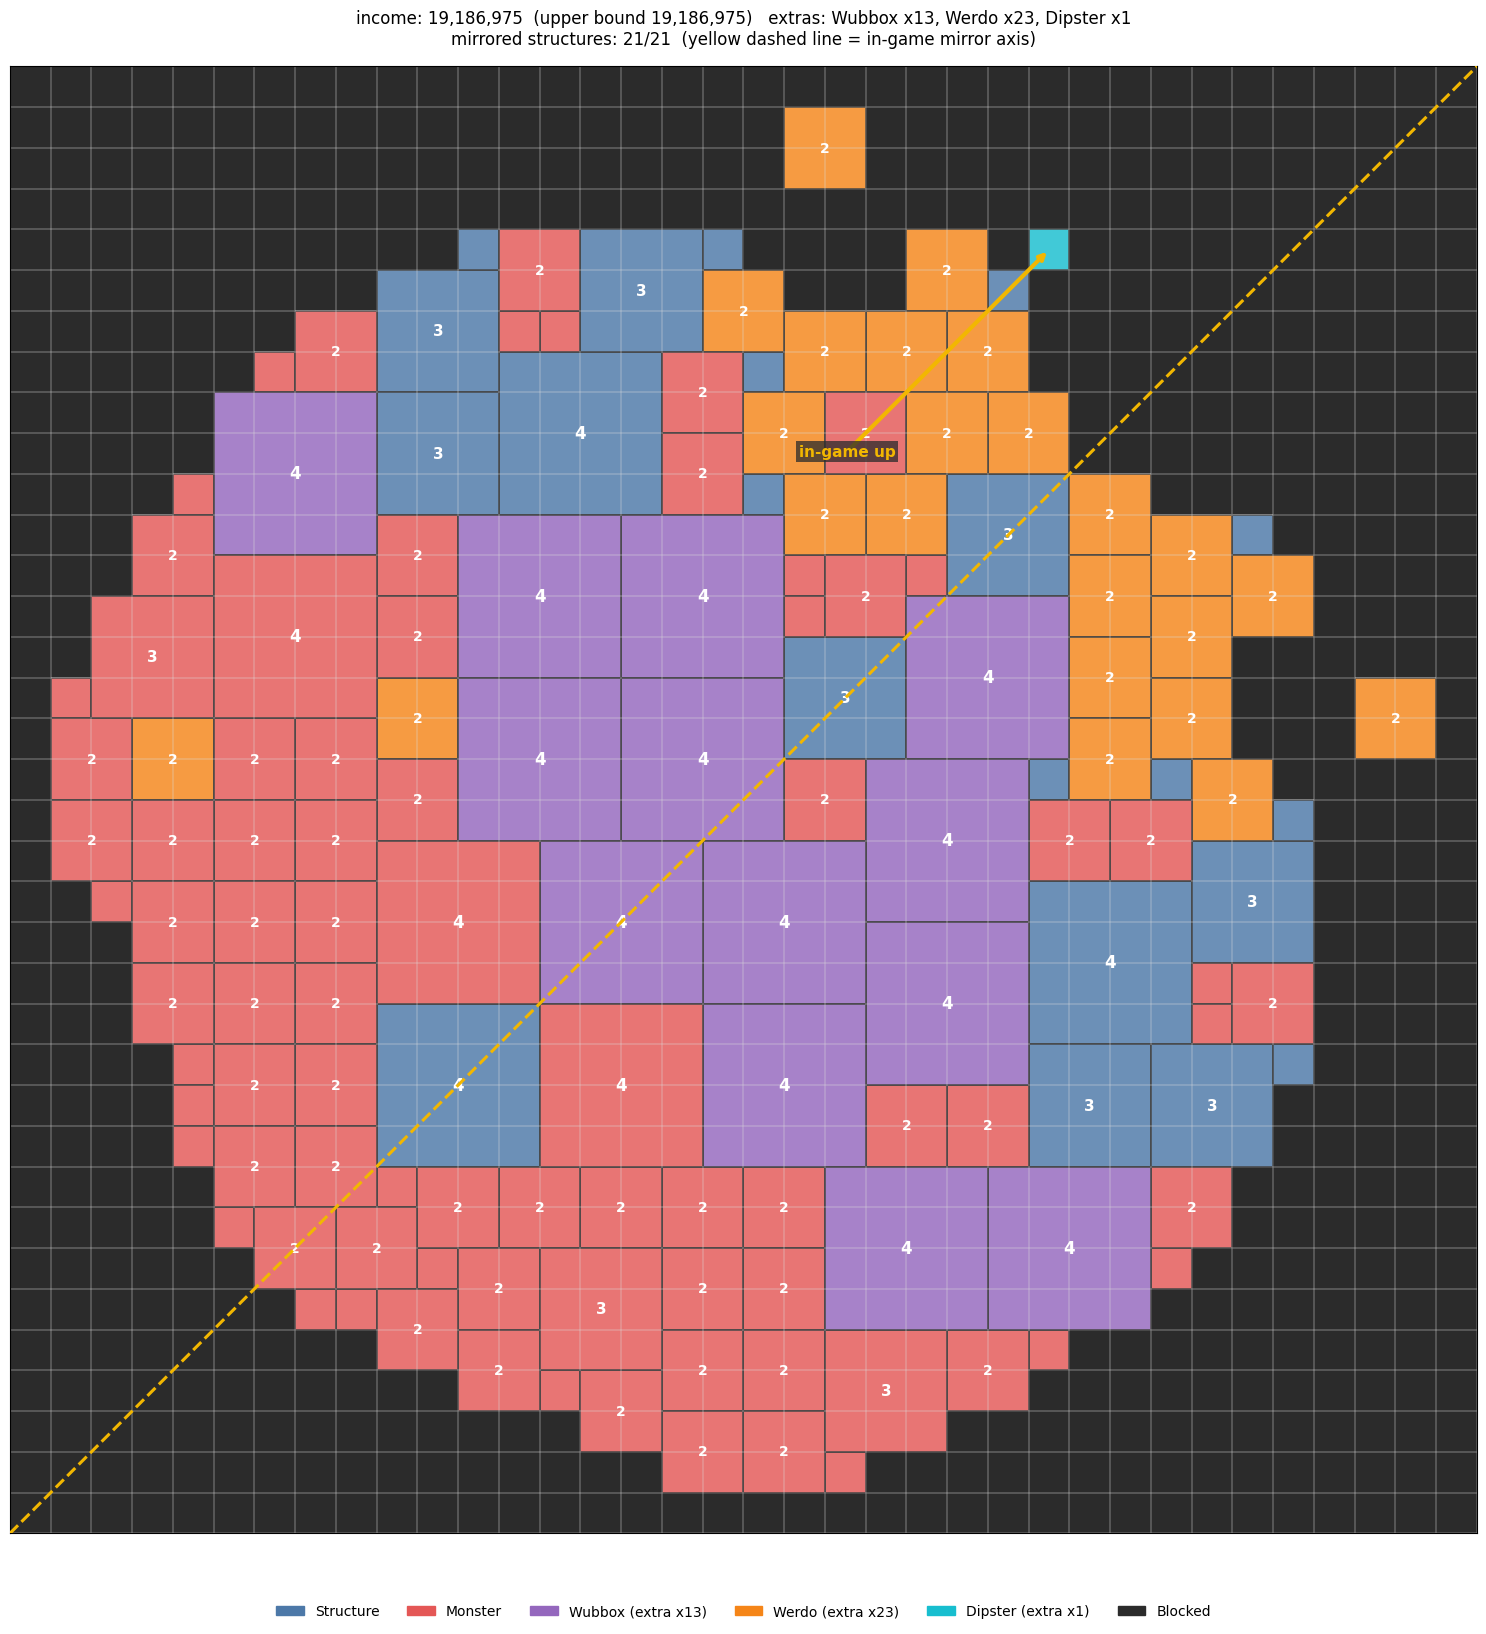

PermissionError: [Errno 13] Permission denied: 'Plant.xlsx'

In [3]:
# ── Run (no editing needed) ──────────────────────────────────────────────────
avail = load_avail_from_csv(CSV_PATH, log=LOG)

sol = solve_full_collection_with_fill(
    avail, structures, monsters,
    log=LOG,
    solver_log=SOLVER_LOG,
    workers=WORKERS,
    max_time_in_seconds=None if RUN_TO_OPTIMAL else MAX_SOLVE_SECS,
    fill_size=FILL_SIZE,
    fill_leftovers=FILL_LEFTOVERS,
    structure_symmetry=STRUCTURE_SYMMETRY,
    monster_catalog=monster_catalog if USE_INCOME else None,
    gradient_gap=GRADIENT_GAP,
    gradient_time_limit=GRADIENT_MAX_SECS,
    height_mode=HEIGHT_MODE,
    flip_up=FLIP_UP,
)

if not sol["ok"]:
    print("FAILED:", sol.get("reason") or sol.get("status"))
else:
    # Full legality check: exact counts, no overlaps, nothing on a blocked cell.
    problems = validate_solution(avail, sol, structures, sol["monsters"])
    if problems:
        raise AssertionError("Invalid layout:\n  " + "\n  ".join(problems))

    fs = sol["fill_size"]
    short = sol["fill_upper_bound"] - sol["fill_count"]
    print(f"Structures: {sol['structures']}")
    print(f"Monsters:   {sol['monsters']}")
    if sol["monster_mix"] is not None:
        print(f"Extras:     {sol['monster_mix']}")
        if sol["remaining_beds"] is not None:
            print(f"Beds:       {sol['beds_used']}/{sol['remaining_beds']} used")
        print(f"Income:     {sol['income']:,}"
              + ("  (proven maximum)" if sol["fill_optimal"]
                 else f"  (up to {sol['income_upper_bound']:,} may be possible - raise MAX_SOLVE_SECS)"))
    else:
        print(f"Fill {fs}x{fs}:   {sol['fill_count']}"
              + ("  (proven maximum)" if sol["fill_optimal"]
                 else f"  (up to {short} more may be possible - raise MAX_SOLVE_SECS)"))
    print(f"Free cells: {sol['free_cells']}")
    if sol["symmetry_axis"]:
        print(f"Symmetry:   {sol['symmetric_structures']}/{sol['total_structures']} structures mirrored"
              + ("  (proven best)" if sol["symmetry_optimal"] else f"  (up to {sol['symmetric_structures_bound']} may be possible)"))
    gap = sol["gradient_gap"]
    print(f"Gradient:   {'optimal' if sol['gradient_optimal'] else (f'within {gap:.1%} of best' if gap is not None else 'fallback layout')}")
    print(f"Time:       {sol['phase1_seconds']:.2f}s packing + {sol['symmetry_seconds']:.2f}s symmetry"
          f" + {sol['phase2_seconds']:.2f}s layout"
          f"  ({sol['total_seconds']:.2f}s total)")

    draw_solution(avail, sol)
    print("Saved:", export_solution_to_excel(avail, sol, EXCEL_OUT))


# math

In [ ]:
# # ── Scratch ──────────────────────────────────────────────────────────────────
# werdos  = 408799
# wubbox  = 750855
# dipsters = 23483
# 10 * wubbox + 26 * werdos + 6 * dipsters > 11 * wubbox + 23 * werdos + 2 * dipsters
